## KMeans Algorithm

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [4]:
X,y_true=make_blobs(n_samples=500,centers=3,cluster_std=0.60,
                    random_state=42)

In [7]:
df=pd.DataFrame(X,columns=['Feature_1','Feature_2'])

In [9]:
df

,Feature_1,Feature_2
0,-6.190063,-7.302015
1,3.021747,1.940593
2,5.953761,1.488191
3,-2.744463,8.136177
4,5.360607,1.728324
...,...,...
495,-6.040014,-6.325329
496,-2.555459,9.218977
497,4.438408,2.974583
498,-7.193261,-6.250704


In [12]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(df)

In [13]:
inertia=[]
K_range=range(1,11)

In [15]:
for k in K_range:
    Kmeans=KMeans(n_clusters=k,random_state=42)
    Kmeans.fit(X_scaled)
    inertia.append(Kmeans.inertia_)

In [16]:
inertia

[999.9999999999999,
 297.8954141051722,
 11.575484723104978,
 9.752067977356841,
 8.257175272446283,
 6.9175773204167985,
 6.334755391595289,
 5.704177177901429,
 5.0602341335320755,
 4.762361898130396]

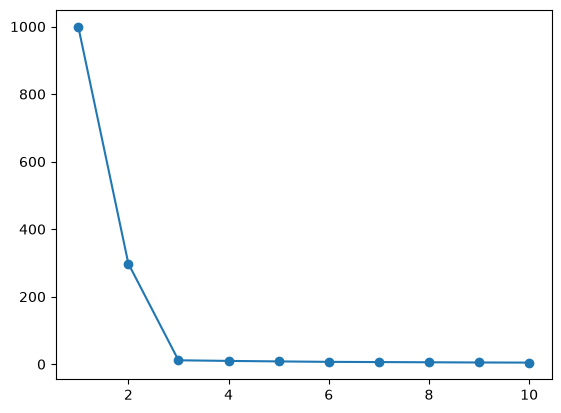

In [20]:
plt.plot(K_range,inertia,marker='o')

In [21]:
Kmeans_final=KMeans(n_clusters=3,random_state=42)

In [22]:
cluster_labels=Kmeans_final.fit_predict(X_scaled)

In [23]:
df['cluster']=cluster_labels

<Axes: xlabel='Feature_1', ylabel='Feature_2'>

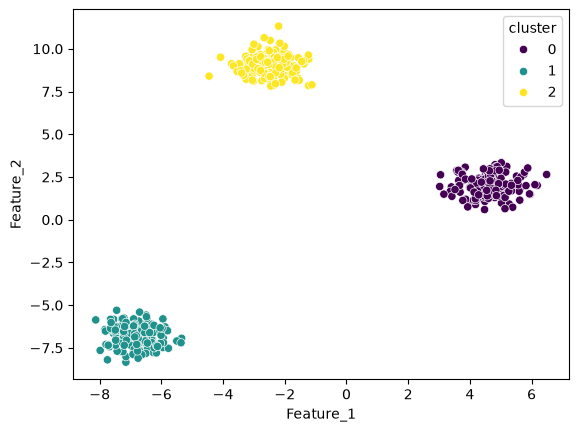

In [24]:
sns.scatterplot(x=df['Feature_1'],
                y=df['Feature_2'],
                hue=df['cluster'],
                palette='viridis')

## DB SCAN Algorithm

In [25]:
from sklearn.datasets import make_moons

In [28]:
X,y_true=make_moons(n_samples=500,noise=0.05,
                    random_state=42)

In [50]:
from sklearn.cluster import KMeans,DBSCAN

In [69]:
df=pd.DataFrame(X, columns=['Feature_1','Feature_2'])

In [70]:
scaler=StandardScaler()
x_scaled=scaler.fit_transform(df)

In [71]:
kmeans=KMeans(n_clusters=2,random_state=42, n_init=10)
kmeans_labels=kmeans.fit_predict(X_scaled)

In [72]:
df['kmeans_cluster']=kmeans_labels

Text(0.5, 1.0, 'K-Means Clustering')

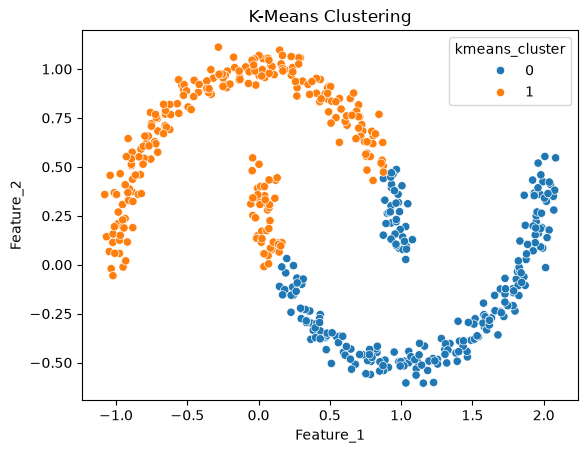

In [73]:
sns.scatterplot(
    data=df,
    x='Feature_1',
    y='Feature_2',
    hue='kmeans_cluster',
    palette='tab10'
)
plt.title('K-Means Clustering')

In [74]:
dbscan = DBSCAN(eps=0.3, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

In [75]:
df['dbscan_cluster']=dbscan_labels

Text(0.5, 1.0, 'K-Means Clustering')

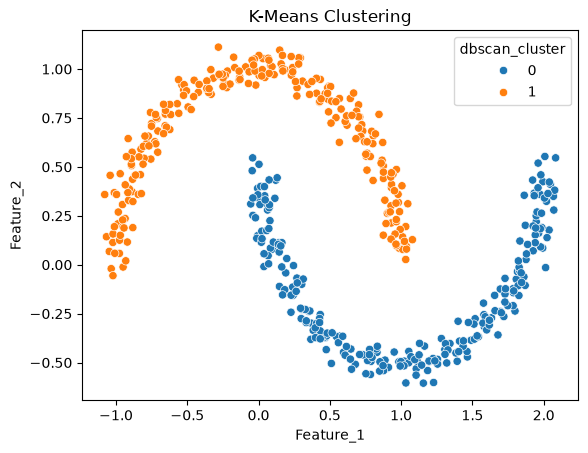

In [77]:
sns.scatterplot(
    data=df,
    x='Feature_1',
    y='Feature_2',
    hue='dbscan_cluster',
    palette='tab10'
)
plt.title('K-Means Clustering')